<a href="https://colab.research.google.com/github/alsedawy/AI/blob/main/copy_of_tinynet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

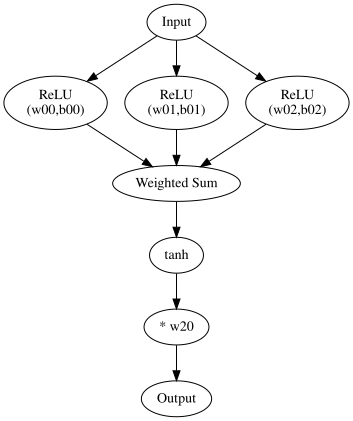

------------------------------
Starting Training (He Init)...
------------------------------
Epoch: 0 | Loss: 1.71552801
Epoch: 400 | Loss: 0.00152002
Epoch: 800 | Loss: 0.00093185
Epoch: 1200 | Loss: 0.00085910
Epoch: 1600 | Loss: 0.00081062
Epoch: 2000 | Loss: 0.00076135


/tmp/ipykernel_630/1704387163.py:151: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_630/1704387163.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


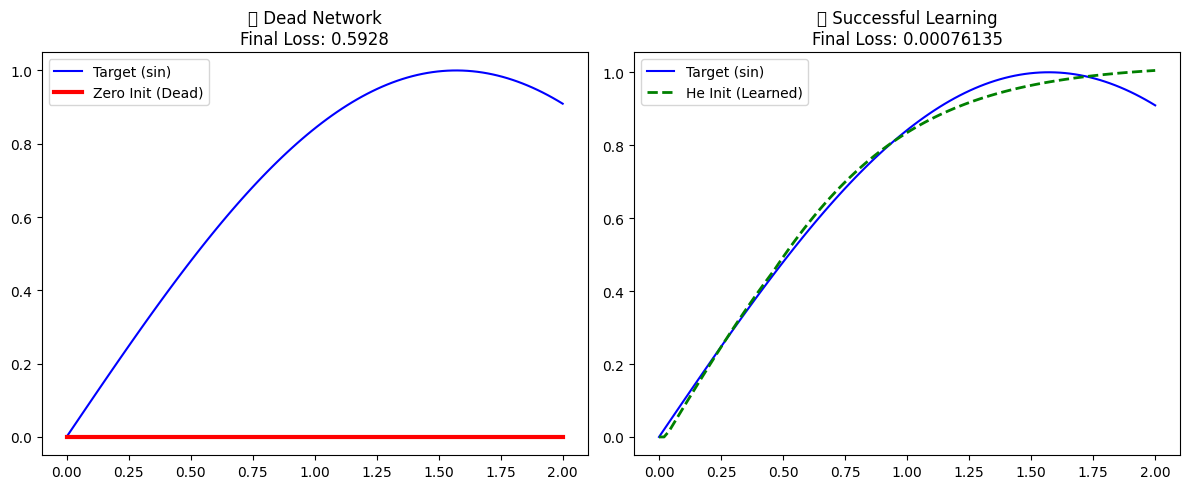

In [23]:
# ==============================
# 1️⃣ رسم الشبكة
# ==============================

from graphviz import Digraph

dot = Digraph()

dot.node('x','Input')

dot.node('l1','ReLU\n(w00,b00)')
dot.node('l2','ReLU\n(w01,b01)')
dot.node('l3','ReLU\n(w02,b02)')

dot.edge('x','l1')
dot.edge('x','l2')
dot.edge('x','l3')

dot.node('sum','Weighted Sum')
dot.edge('l1','sum')
dot.edge('l2','sum')
dot.edge('l3','sum')

dot.node('tanh','tanh')
dot.edge('sum','tanh')

dot.node('w20','* w20')
dot.edge('tanh','w20')

dot.node('out','Output')
dot.edge('w20','out')

display(dot)

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1️⃣ تحضير البيانات (Target: Sine Wave)
# ==========================================
# توليد 100 نقطة لتمثيل دالة الجا (Sin)
x = torch.linspace(0, 2, 100).reshape(-1, 1)
y_true = torch.sin(x)

# ==========================================
# 2️⃣ نموذج التصفير (❌ Zero Initialization)
# ==========================================
class TinyNetZero(nn.Module):
    def __init__(self):
        super().__init__()
        # بدء جميع الأوزان والانحيازات بصفر
        def zero_p(): return nn.Parameter(torch.tensor(0.0))

        self.w00 = zero_p(); self.b00 = zero_p()
        self.w01 = zero_p(); self.b01 = zero_p()
        self.w02 = zero_p(); self.b02 = zero_p()
        self.w11 = zero_p(); self.w12 = zero_p(); self.w13 = zero_p()
        self.w20 = zero_p()

    def forward(self, x):
        l1 = torch.relu(x * self.w00 + self.b00)
        l2 = torch.relu(x * self.w01 + self.b01)
        l3 = torch.relu(x * self.w02 + self.b02)
        s = l1 * self.w11 + l2 * self.w12 + l3 * self.w13
        return torch.tanh(s) * self.w20

# ==========================================
# 3️⃣ نموذج النجاح (✅ He Initialization)
# ==========================================
class TinyNetHe(nn.Module):
    def __init__(self):
        super().__init__()
        # He Init formula: std = sqrt(2 / fan_in)
        def he_init(f_in):
            return nn.Parameter(torch.randn(1) * torch.sqrt(torch.tensor(2.0/f_in)))

        # الطبقة الأولى (fan_in = 1)
        self.w00 = he_init(1); self.b00 = nn.Parameter(torch.tensor(0.1))
        self.w01 = he_init(1); self.b01 = nn.Parameter(torch.tensor(0.1))
        self.w02 = he_init(1); self.b02 = nn.Parameter(torch.tensor(0.1))

        # الطبقة الثانية (fan_in = 3)
        self.w11 = he_init(3); self.w12 = he_init(3); self.w13 = he_init(3)
        self.w20 = he_init(3)

    def forward(self, x):
        l1 = torch.relu(x * self.w00 + self.b00)
        l2 = torch.relu(x * self.w01 + self.b01)
        l3 = torch.relu(x * self.w02 + self.b02)
        s = l1 * self.w11 + l2 * self.w12 + l3 * self.w13
        return torch.tanh(s) * self.w20

# ==========================================
# 4️⃣ تنفيذ التجارب (Execution)
# ==========================================
loss_fn = nn.MSELoss()

# --- تجربة التصفير (لإثبات الفشل) ---
model_z = TinyNetZero()
opt_z = optim.SGD(model_z.parameters(), lr=0.05)
for e in range(1001):
    p = model_z(x); l_z = loss_fn(p, y_true)
    opt_z.zero_grad(); l_z.backward(); opt_z.step()

# --- تجربة He (لإثبات النجاح والتعلم) ---
model_h = TinyNetHe()
opt_h = optim.Adam(model_h.parameters(), lr=0.01)

print("-" * 30)
print("Starting Training (He Init)...")
print("-" * 30)

for e in range(2001):
    p_h = model_h(x)
    l_h = loss_fn(p_h, y_true)

    opt_h.zero_grad()
    l_h.backward()
    opt_h.step()

    # طبقة النتائج بالتنسيق المطلوب
    if e % 400 == 0:
        print(f"Epoch: {e} | Loss: {l_h.item():.8f}")

# ==========================================
# 5️⃣ رسم المقارنة البصرية
# ==========================================
with torch.no_grad():
    y_z = model_z(x)
    y_h = model_h(x)

plt.figure(figsize=(12, 5))

# رسمة الفشل (Zero Init)
plt.subplot(1, 2, 1)
plt.plot(x.numpy(), y_true.numpy(), label="Target (sin)", color='blue')
plt.plot(x.numpy(), y_z.numpy(), label="Zero Init (Dead)", color='red', linewidth=3)
plt.title(f"❌ Dead Network\nFinal Loss: {l_z.item():.4f}")
plt.legend()

# رسمة النجاح (He Init)
plt.subplot(1, 2, 2)
plt.plot(x.numpy(), y_true.numpy(), label="Target (sin)", color='blue')
plt.plot(x.numpy(), y_h.numpy(), '--', label="He Init (Learned)", color='green', linewidth=2)
plt.title(f"✅ Successful Learning\nFinal Loss: {l_h.item():.8f}")
plt.legend()

plt.tight_layout()
plt.show()